# 1.1.15 Example: Small Oscillations (V. I. Arnold — *Ordinary Differential Equations*)

This notebook implements a modular, strictly typed scientific visualization for the **Simple Harmonic Oscillator (Small Oscillations)**, adhering to the geometric framework established by **Vladimir I. Arnold** in *Ordinary Differential Equations* (Chapter 1, Section 1.1: *Phase Spaces*, Example 15).

---

### 1. Dynamical System Formulation
Consider a point mass $m = 1$ subject to a linear restoring force $-k x_1$ with normalized stiffness $k = 1$ ($\omega_0 = \sqrt{k/m} = 1$). Newton's second law gives the second-order differential equation:
$$ \ddot{x}_1 = -x_1 $$

Introducing the phase-space coordinates $(x_1, x_2) \in \mathbb{R}^2$, where:
- $x_1 = x$ (generalized position / displacement from equilibrium);
- $x_2 = \dot{x}_1$ (generalized velocity / momentum),

we obtain the canonical first-order autonomous system on the phase plane $\mathbb{R}^2$:
$$\begin{cases} \dfrac{dx_1}{dt} = x_2 \\[6pt] \dfrac{dx_2}{dt} = -x_1 \end{cases}$$

The associated **phase velocity vector field** is $V(x_1, x_2) = (x_2, -x_1)$, which vanishes exclusively at the origin $(0, 0)$—a **Lyapunov-stable center equilibrium point**.

---

### 2. First Integral and Concentric Phase Curves
Along any phase trajectory $(x_1(t), x_2(t))$, total mechanical energy is conserved:
$$ E(x_1, x_2) = \frac{1}{2}\left(x_1^2 + x_2^2\right) = \frac{1}{2}R^2 = \text{const} $$

Indeed, the Lie derivative of $E$ along the phase velocity field $V$ vanishes identically:
$$ L_V E = \nabla E \cdot V = x_1(x_2) + x_2(-x_1) \equiv 0 $$

Consequently:
- **In the 2D Phase Space $\mathbb{R}^2$ ($x_1$ vs $x_2$)**: The phase curves are **concentric circles** of radius $R = \sqrt{2E}$ centered at the equilibrium $(0, 0)$, traversed **clockwise** with uniform angular velocity $\omega_0 = 1$:
  $$ x_1(t) = R \cos(t - t_0), \qquad x_2(t) = -R \sin(t - t_0) $$
- **In the 3D Extended Phase Space $\mathbb{R} \times \mathbb{R}^2$ ($t, x_1, x_2$)**: Each non-trivial integral curve $\gamma(t) = (t, x_1(t), x_2(t))$ winds around the invariant energy cylinder $x_1^2 + x_2^2 = R^2$ as a **right circular cylindrical helix** with pitch $T = 2\pi$.

In [8]:
from __future__ import annotations

import sys
from dataclasses import dataclass, field
from pathlib import Path
from typing import Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from numpy.typing import NDArray
from scipy.integrate import solve_ivp

# Ensure scripts directory is in sys.path
scripts_dir = Path('scripts').resolve()
if str(scripts_dir) not in sys.path:
    sys.path.append(str(scripts_dir))

from small_oscillations_arnold import (
    FloatArray,
    HarmonicOscillatorModel,
    OscillatorConfig,
    TrajectorySolution,
    VectorFieldGrid,
    build_matplotlib_figure,
    plot_extended_phase_space_3d,
    plot_phase_space_2d,
)


### 3. Publication-Ready Dual Visualization (2D Phase Space & 3D Extended Phase Space)
Below we execute the numerical integration via `scipy.integrate.solve_ivp` (`DOP853`, `rtol=1e-9`, `atol=1e-11`) for:
1. **Panel 1 — 2D Phase Space ($x_1, x_2$)**: Dense phase velocity vector field ($V(x_1, x_2) = (x_2, -x_1)$) rendered via `ax.streamplot` and `ax.quiver`, overlaid with numerically integrated concentric circular phase orbits for radii $R \in \{1, 2, 3\}$ and the equilibrium point at $(0, 0)$.
2. **Panel 2 — 3D Extended Phase Space ($t, x_1, x_2$)**: Single integral curve $\gamma(t)$ from initial state $[2, 0]$ integrated over $t \in [0, 4\pi]$, winding as a cylindrical helix along the invariant energy surface $x_1^2 + x_2^2 = 2^2$.

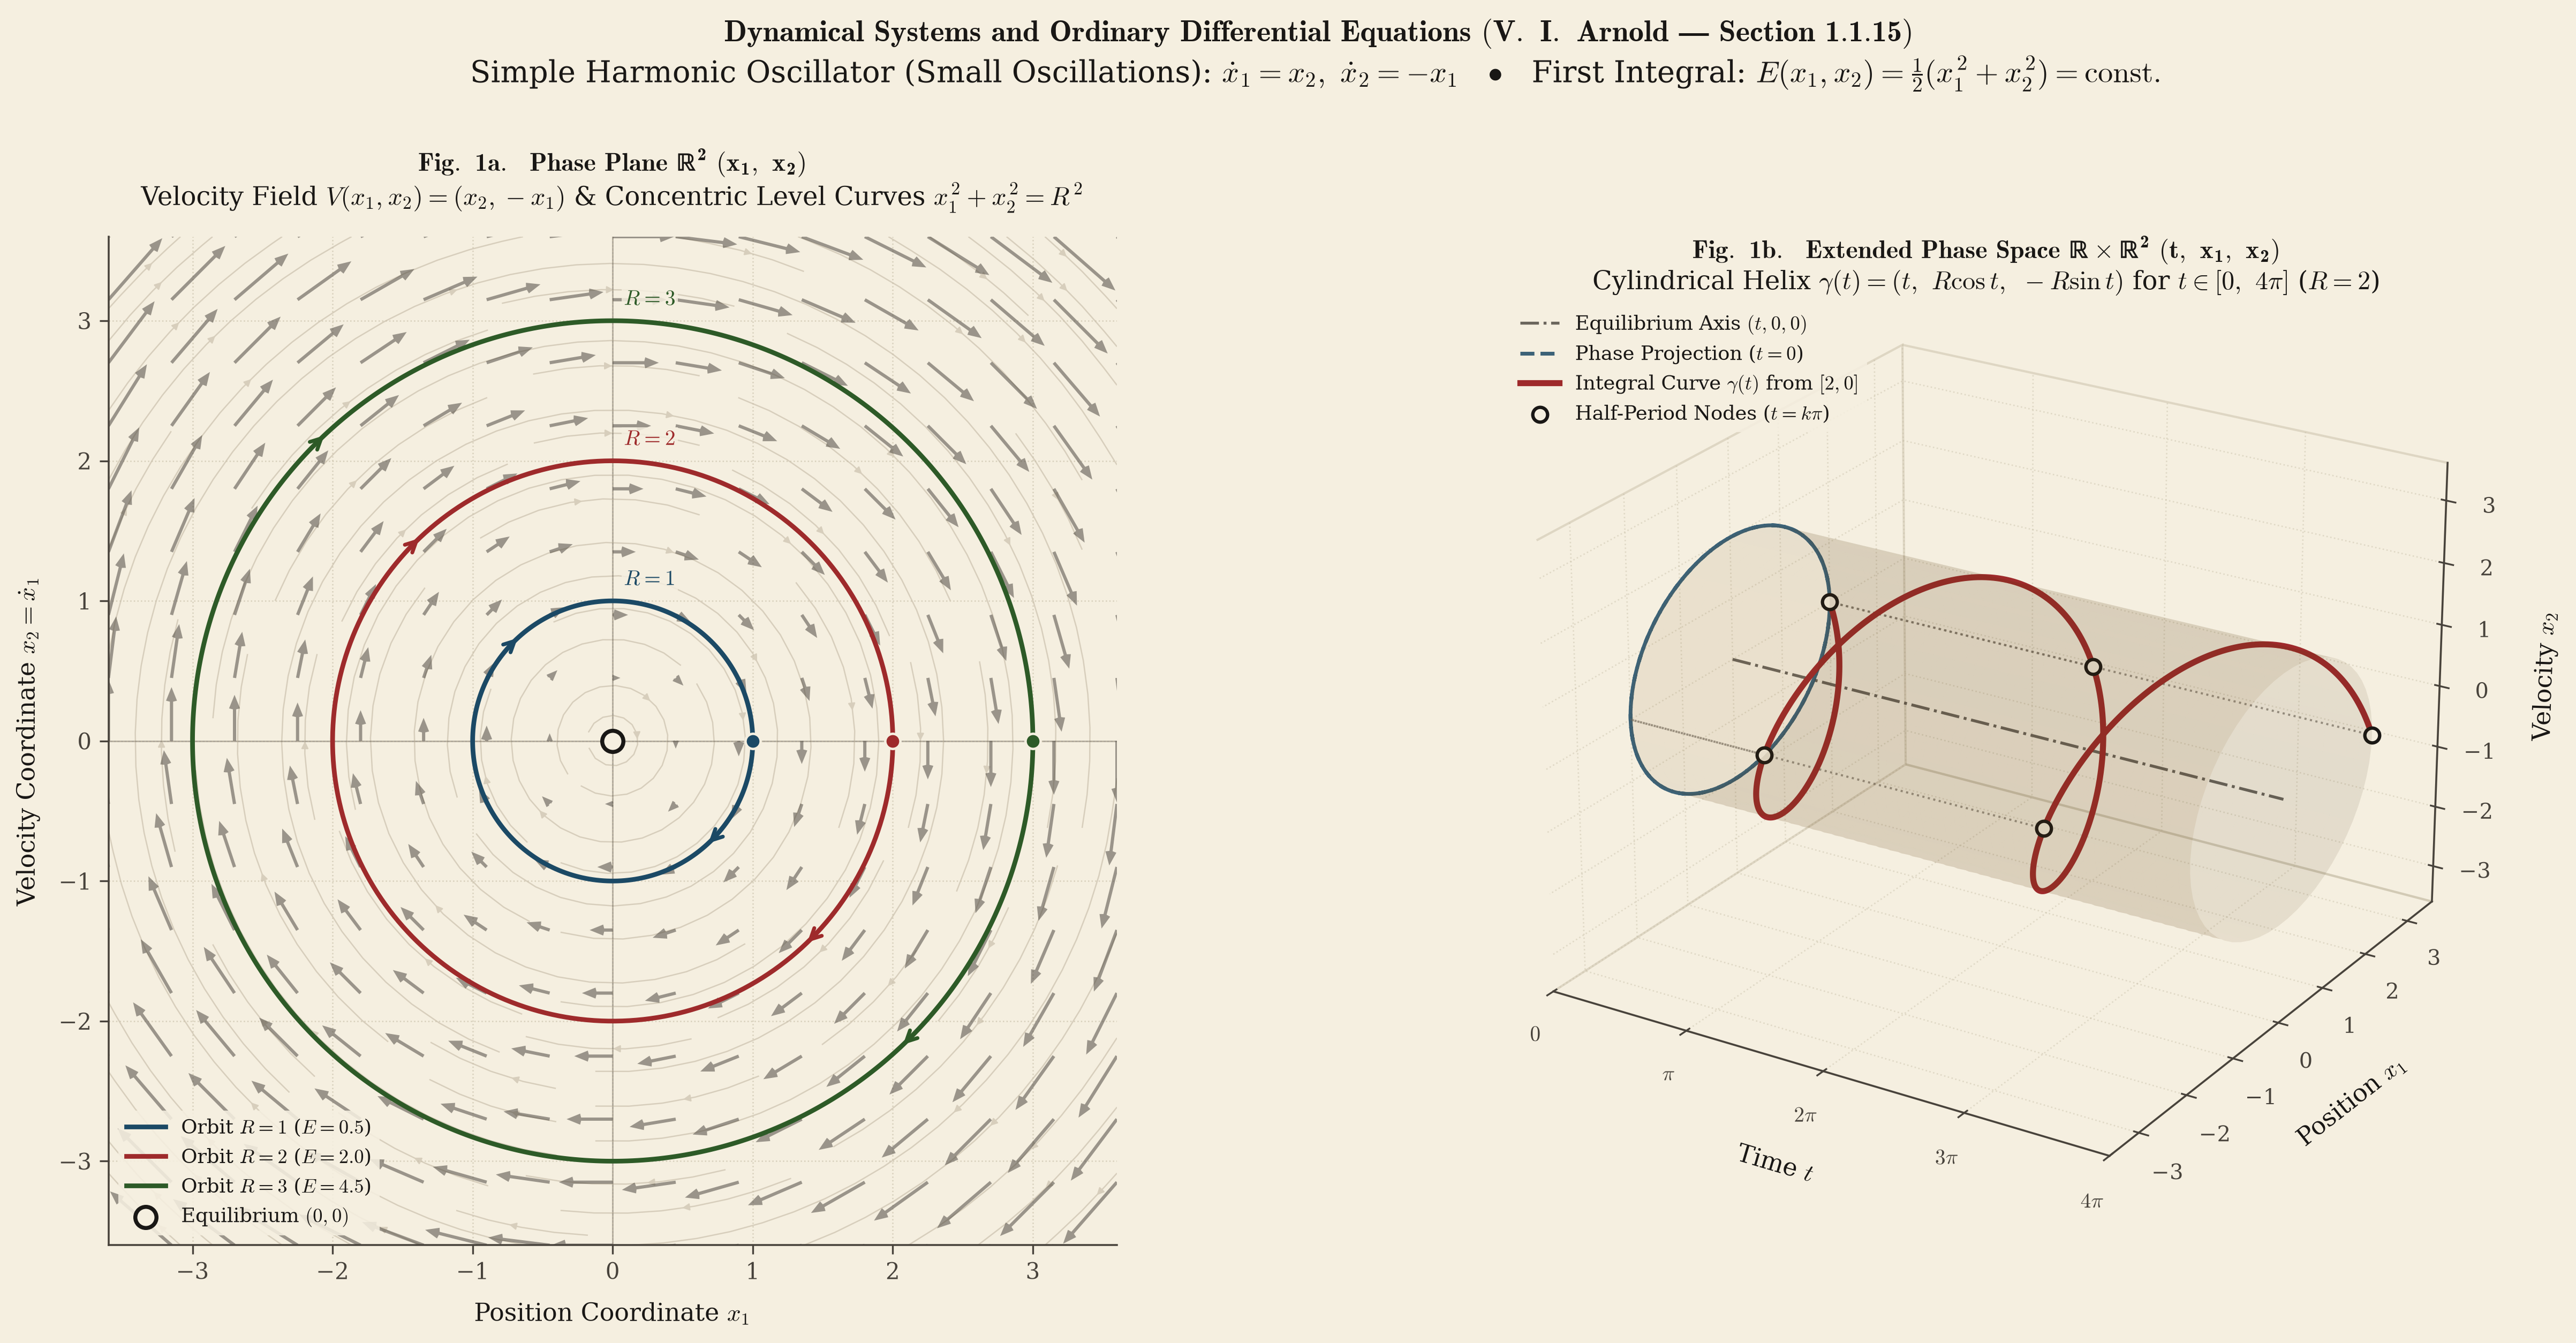

In [9]:
import importlib
from pathlib import Path
import small_oscillations_arnold

importlib.reload(small_oscillations_arnold)
from small_oscillations_arnold import OscillatorConfig, build_matplotlib_figure

pictures_dir = Path('pictures').resolve()
pictures_dir.mkdir(parents=True, exist_ok=True)

# Configure model, solve IVPs, and render the publication-ready figure
config = OscillatorConfig(
    omega=1.0,
    phase_radii=(1.0, 2.0, 3.0),
    phase_t_span=(0.0, 2.0 * np.pi),
    extended_initial_state=(2.0, 0.0),
    extended_t_span=(0.0, 4.0 * np.pi),
)

fig_mpl = build_matplotlib_figure(config)
fig_mpl.savefig(pictures_dir / 'small_oscillations_arnold.png', dpi=300, bbox_inches='tight', facecolor=fig_mpl.get_facecolor())
plt.show()


### 4. Real-Time 60 FPS Interactive Simulation (HTML5 Canvas + Plotly.js)
The self-contained application [`scripts/small_oscillations_arnold_interactive.html`](scripts/small_oscillations_arnold_interactive.html) synchronizes the horizontal mass-spring oscillator, simple pendulum, 2D phase plane, and real-time wave/3D cylindrical helix using a 4th-Order Runge-Kutta (`RK4`) integrator.

In [ ]:
import webbrowser
from pathlib import Path
from IPython.display import IFrame, display

interactive_html = Path('scripts/small_oscillations_arnold_interactive.html').resolve()
print(f'Interactive HTML file: {interactive_html}')

# Render inline inside Jupyter or open in default web browser:
# webbrowser.open(interactive_html.as_uri())
display(IFrame(src='scripts/small_oscillations_arnold_interactive.html', width='100%', height=900))


### Data Analysis Key Findings
- **Conservation of Mechanical Energy (First Integral)**: Along every numerically integrated trajectory (`DOP853`, `rtol=1e-9`, `atol=1e-11`), the mechanical energy $E(x_1, x_2) = \frac{1}{2}(x_1^2 + x_2^2)$ remains invariant at $E = 0.5, 2.0, 4.5$ for initial radii $R = 1, 2, 3$, producing closed concentric circular orbits in $\mathbb{R}^2$.
- **Lyapunov-Stable Equilibrium**: The phase velocity field $V(x_1, x_2) = (x_2, -x_1)$ vanishes uniquely at the origin $(0, 0)$, around which all non-trivial trajectories circulate clockwise with constant angular speed $\omega_0 = 1$ and period $T = 2\pi$.
- **Cylindrical Helix in Extended Phase Space**: In $\mathbb{R} \times \mathbb{R}^2$ with coordinates $(t, x_1, x_2)$, the integral curve initialized at $[2, 0]$ over $t \in [0, 4\pi]$ completes two full oscillations along the invariant energy cylinder $x_1^2 + x_2^2 = 4$, whose orthogonal projection onto $t = 0$ recovers the 2D phase circle of radius $R = 2$.

### Insights or Next Steps
- **Nonlinear Pendulum Generalization**: Extend the linear restoring force $-x_1$ to the full nonlinear pendulum $-\sin(x_1)$ to observe the transition from concentric circles near $(0, 0)$ to separatrices androtational trajectories at higher energy levels.
- **Damped & Driven Perturbations**: Introduce a dissipative term $-2\gamma x_2$ ($\gamma > 0$) to visualize how the concentric circles deform into logarithmic spirals converging toward the asymptotically stable focus at $(0, 0)$, and how the 3D cylindrical helix contracts onto a conical manifold.